In [4]:
import pandas as pd

In [5]:
df = pd.read_csv("D:\\Data science\\codes\\files\\Medical Cost Prediction.csv")
df

,Patient_ID,Age,Gender,BMI,Smoker,Region,Children,Medical_History,Daily_Exercise,Annual_Income,Insurance_Premium,Blood_Pressure,Cholesterol,Chronic_Diseases,Recent_Hospital_Visits,Stress_Level,Medical Costs
0,1001,52,Male,28.0,No,Northeast,1,0,1.5,70000,2000,120/80,200,0,2,4,18000
1,1002,45,Female,33.5,Yes,Northwest,2,1,1.0,60000,1500,130/85,220,1,1,5,24000
2,1003,36,Male,22.1,No,Southeast,0,0,2.5,80000,1800,115/75,180,0,0,3,15000
3,1004,50,Male,25.3,Yes,Southwest,3,2,1.0,100000,2200,122/78,240,2,3,7,35000
4,1005,31,Female,29.8,No,Northwest,1,0,1.5,55000,1600,128/82,200,0,1,2,12000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
275,1276,31,Female,28.9,No,Southwest,1,0,2.0,70000,2000,130/85,250,0,1,3,11000
276,1277,64,Male,31.2,No,Northwest,2,3,0.5,120000,2500,135/88,230,3,2,5,42000
277,1278,30,Female,26.5,No,Northeast,0,0,2.5,65000,1700,130/85,250,0,1,2,14000
278,1279,57,Male,30.4,Yes,Northwest,1,2,1.0,95000,2300,128/83,240,2,0,6,30000


In [6]:
df.isnull().sum()

Patient_ID                0
Age                       0
Gender                    0
BMI                       0
Smoker                    0
Region                    0
Children                  0
Medical_History           0
Daily_Exercise            0
Annual_Income             0
Insurance_Premium         0
Blood_Pressure            0
Cholesterol               0
Chronic_Diseases          0
Recent_Hospital_Visits    0
Stress_Level              0
Medical Costs             0
dtype: int64

In [7]:
from sklearn.preprocessing import LabelEncoder

for column in ['Gender', 'Smoker', 'Region']:
    le = LabelEncoder()
    df[column] = le.fit_transform(df[column])

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 280 entries, 0 to 279
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Patient_ID              280 non-null    int64  
 1   Age                     280 non-null    int64  
 2   Gender                  280 non-null    int32  
 3   BMI                     280 non-null    float64
 4   Smoker                  280 non-null    int32  
 5   Region                  280 non-null    int32  
 6   Children                280 non-null    int64  
 7   Medical_History         280 non-null    int64  
 8   Daily_Exercise          280 non-null    float64
 9   Annual_Income           280 non-null    int64  
 10  Insurance_Premium       280 non-null    int64  
 11  Blood_Pressure          280 non-null    object 
 12  Cholesterol             280 non-null    int64  
 13  Chronic_Diseases        280 non-null    int64  
 14  Recent_Hospital_Visits  280 non-null    in

In [8]:
if 'Blood_Pressure' in df.columns and df['Blood_Pressure'].str.contains('/').any():
    df[['Systolic_BP', 'Diastolic_BP']] = df['Blood_Pressure'].str.split('/',expand=True)
    df = df.drop(columns=['Blood_Pressure'])
    print(df.head())
else:
    print("Blood_Pressure column not found")

   Patient_ID  Age  Gender   BMI  Smoker  Region  Children  Medical_History  \
0        1001   52       1  28.0       0       0         1                0   
1        1002   45       0  33.5       1       1         2                1   
2        1003   36       1  22.1       0       2         0                0   
3        1004   50       1  25.3       1       3         3                2   
4        1005   31       0  29.8       0       1         1                0   

   Daily_Exercise  Annual_Income  Insurance_Premium  Cholesterol  \
0             1.5          70000               2000          200   
1             1.0          60000               1500          220   
2             2.5          80000               1800          180   
3             1.0         100000               2200          240   
4             1.5          55000               1600          200   

   Chronic_Diseases  Recent_Hospital_Visits  Stress_Level  Medical Costs  \
0                 0                     

In [9]:
df[['Systolic_BP', 'Diastolic_BP']] = df[['Systolic_BP', 'Diastolic_BP']].astype(int)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 280 entries, 0 to 279
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Patient_ID              280 non-null    int64  
 1   Age                     280 non-null    int64  
 2   Gender                  280 non-null    int32  
 3   BMI                     280 non-null    float64
 4   Smoker                  280 non-null    int32  
 5   Region                  280 non-null    int32  
 6   Children                280 non-null    int64  
 7   Medical_History         280 non-null    int64  
 8   Daily_Exercise          280 non-null    float64
 9   Annual_Income           280 non-null    int64  
 10  Insurance_Premium       280 non-null    int64  
 11  Cholesterol             280 non-null    int64  
 12  Chronic_Diseases        280 non-null    int64  
 13  Recent_Hospital_Visits  280 non-null    int64  
 14  Stress_Level            280 non-null    in

In [11]:
from sklearn.preprocessing import StandardScaler

columns_to_scale = [col for col in df.columns if col not in ['Patient_ID', 'Medical Costs']]
ss = StandardScaler()

df[columns_to_scale] = ss.fit_transform(df[columns_to_scale])

df.head()

,Patient_ID,Age,Gender,BMI,Smoker,Region,Children,Medical_History,Daily_Exercise,Annual_Income,Insurance_Premium,Cholesterol,Chronic_Diseases,Recent_Hospital_Visits,Stress_Level,Medical Costs,Systolic_BP,Diastolic_BP
0,1001,0.547916,0.911079,-0.315870,-0.582849,-1.348370,-0.080271,-0.794201,0.049171,-0.608382,0.151857,-1.181708,-0.794201,1.083862,-0.153016,18000,-1.606563,-1.334182
1,1002,-0.045407,-1.097599,2.089866,1.715710,-0.420744,0.941355,0.057815,-0.606441,-1.182909,-1.680905,-0.222641,0.057815,-0.295599,0.496142,24000,0.124247,0.196847
2,1003,-0.808252,0.911079,-2.896568,-0.582849,0.506881,-1.101896,-0.794201,1.360395,-0.033856,-0.581247,-2.140775,-0.794201,-1.675060,-0.802173,15000,-2.471969,-2.865211
3,1004,0.378395,0.911079,-1.496867,1.715710,1.434506,1.962981,0.909832,-0.606441,1.115197,0.884962,0.736427,0.909832,2.463323,1.794457,35000,-1.260401,-1.946594
4,1005,-1.232054,-1.097599,0.471462,-0.582849,-0.420744,-0.080271,-0.794201,0.049171,-1.470172,-1.314352,-1.181708,-0.794201,-0.295599,-1.451331,12000,-0.221915,-0.721771


In [14]:
X = df.drop(['Patient_ID', 'Medical Costs'], axis= 1)
Y = df['Medical Costs']
X.shape

(280, 16)

input layers should be equal to no of columns  
n = no of input layers  
n --> that implies 16 layers of columns in input  
n = 16  
so hidden layers m = n + (n/2)  
--> 16 + 8 = 24

In [ ]:
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.2, random_state=42)

model = keras.Sequential([
    keras.layers.Input(shape=(X_train.shape[1],)), # input layer
    keras.layers.Dense(24, activation='relu'), # hidden layer with 24 units and relu activation
    keras.layers.Dense(1), # output layer (single nuron for regression)
])

#compile model
# model.compile(optimizer='adam', loss= 'mse', metrics=['r2_score'])
model.compile(optimizer='adam', loss= 'mse', metrics=['mae']) # because no eda done we use Mean absoulate error
# for classification loss == categorical_crossentropy --> called log loss for multi nomial
# for binary loss == binary_crossentropy --> called log loss for multi nomial

binary_crossentropy: For problems like spam detection or a yes/no outcome. The output layer usually has a single neuron with a sigmoid activation.  
categorical_crossentropy: For problems like image classification with multiple possible labels. The output layer has a number of neurons equal to the number of classes, with a softmax activation. 

In [22]:
history = model.fit(X_train, Y_train, epochs=1000, batch_size=32, validation_split=0.2)

Epoch 1/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 652731840.0000 - mae: 23496.5801 - val_loss: 654463104.0000 - val_mae: 23688.3340
Epoch 2/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 652722560.0000 - mae: 23496.4219 - val_loss: 654454016.0000 - val_mae: 23688.1719
Epoch 3/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 652713408.0000 - mae: 23496.2598 - val_loss: 654444672.0000 - val_mae: 23688.0117
Epoch 4/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 652704128.0000 - mae: 23496.0996 - val_loss: 654435392.0000 - val_mae: 23687.8477
Epoch 5/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 652694400.0000 - mae: 23495.9336 - val_loss: 654425728.0000 - val_mae: 23687.6797
Epoch 6/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 652684480.0000 - mae: 23495.7617 - val_loss: 654415936.0000 - val_mae: 23687.5117
Epoch 7/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 652674688.0000 - mae: 23495.5918 - val_loss: 654405824.0000 - val_mae: 23687.3398
Epoch 8/1000


In [23]:
loss, mae = model.evaluate(X_test,Y_test)
print(mae)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 293113088.0000 - mae: 15614.3750
15614.375


In [25]:
train_loss = history.history['loss']
test_loss = history.history['val_loss']

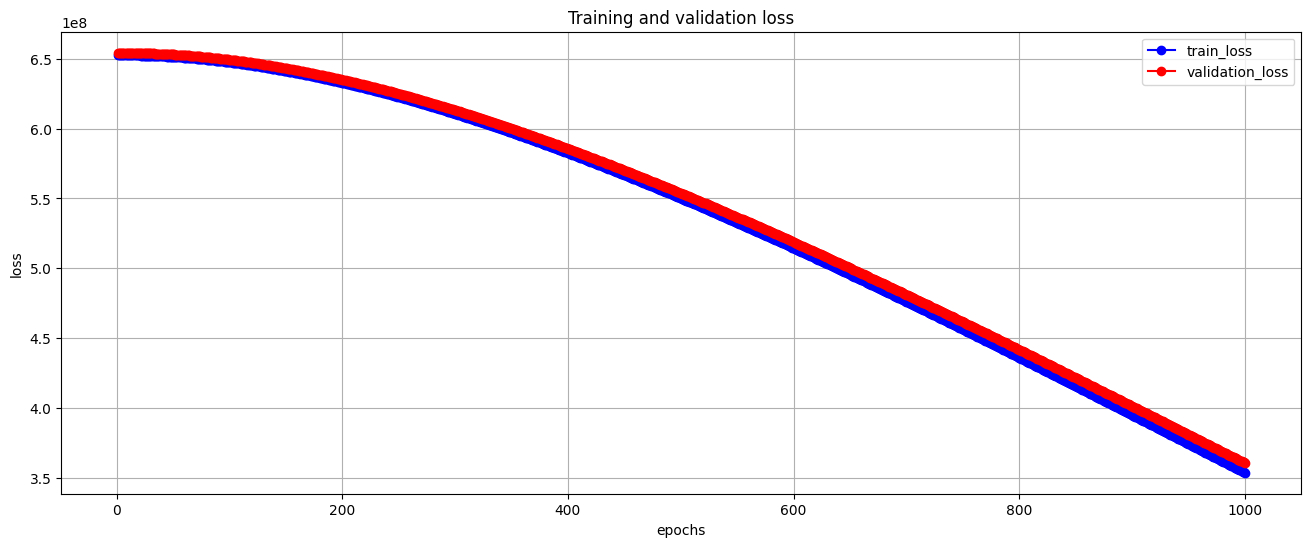

In [26]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_loss) + 1)

plt.figure(figsize=(16,6))
plt.plot(epochs, train_loss, 'bo-', label='train_loss')
plt.plot(epochs, test_loss, 'ro-', label='validation_loss')
plt.title('Training and validation loss')
plt.xlabel('epochs')
plt.ylabel('loss')
plt.legend()
plt.grid(True)
plt.show()

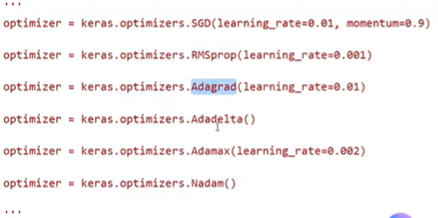